In [2]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

concrete = fetch_ucirepo(id=165)
X = concrete.data.features
y = concrete.data.targets

print(X.shape)
X.head()

(1030, 8)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360


In [3]:
from sklearn.model_selection import train_test_split

y = y.iloc[:, 0]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training mixes:", len(X_train))
print("Test mixes:", len(X_test))

Training mixes: 824
Test mixes: 206


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate(name, model):
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name}: MAE = {mae:.2f} MPa | RMSE = {rmse:.2f} MPa | R² = {r2:.3f}")

baseline = LinearRegression()
baseline.fit(X_train, y_train)
evaluate("Linear regression", baseline)

Linear regression: MAE = 7.75 MPa | RMSE = 9.80 MPa | R² = 0.628


In [5]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(n_estimators=300, random_state=42)
forest.fit(X_train, y_train)
evaluate("Random forest", forest)

Random forest: MAE = 3.79 MPa | RMSE = 5.54 MPa | R² = 0.881


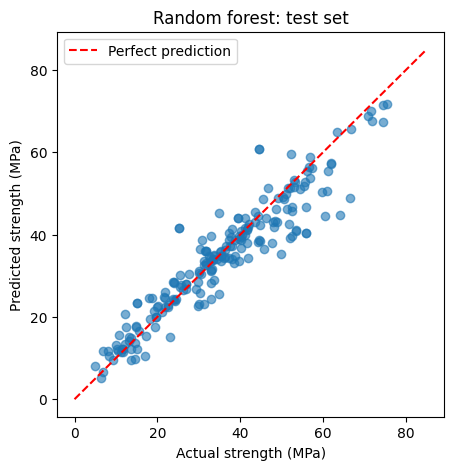

In [6]:
import matplotlib.pyplot as plt

pred = forest.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.6)
plt.plot([0, 85], [0, 85], "r--", label="Perfect prediction")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Random forest: test set")
plt.legend()
plt.savefig("pred_vs_actual.png", dpi=200, bbox_inches="tight")
plt.show()

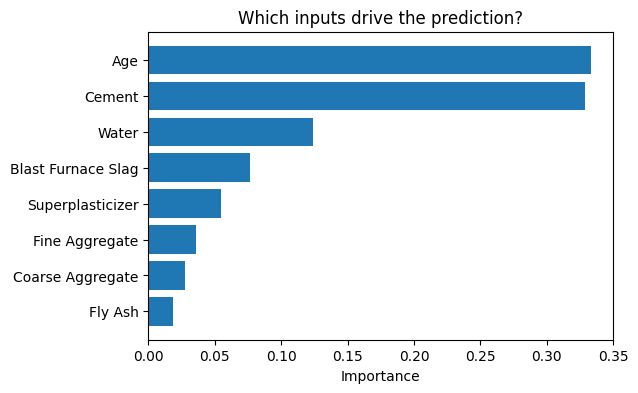

In [7]:
importances = forest.feature_importances_
order = np.argsort(importances)

plt.figure(figsize=(6, 4))
plt.barh(X.columns[order], importances[order])
plt.xlabel("Importance")
plt.title("Which inputs drive the prediction?")
plt.savefig("feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
from sklearn.model_selection import cross_val_score

for name, model in [("Linear regression", LinearRegression()),
                    ("Random forest", RandomForestRegressor(n_estimators=300, random_state=42))]:
    scores = cross_val_score(model, X_train, y_train, cv=5,
                             scoring="neg_mean_absolute_error")
    print(f"{name}: 5-fold CV MAE = {-scores.mean():.2f} ± {scores.std():.2f} MPa")

Linear regression: 5-fold CV MAE = 8.44 ± 0.75 MPa
Random forest: 5-fold CV MAE = 3.60 ± 0.16 MPa


In [9]:
import joblib

joblib.dump(forest, "concrete_rf.joblib")
print("Model saved!")

Model saved!


In [11]:
import pandas as pd

model = joblib.load("concrete_rf.joblib")

new_mix = pd.DataFrame([[350, 0, 0, 175, 5, 1000, 800, 28]], columns=X.columns)

print(f"Predicted 28-day strength: {model.predict(new_mix)[0]:.1f} MPa")

Predicted 28-day strength: 48.7 MPa


In [12]:
import sklearn, pandas, numpy, matplotlib, joblib, sys
print("Python", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("pandas", pandas.__version__)
print("numpy", numpy.__version__)
print("matplotlib", matplotlib.__version__)
print("joblib", joblib.__version__)

Python 3.13.18
scikit-learn 1.6.1
pandas 2.2.3
numpy 2.4.6
matplotlib 3.10.0
joblib 1.6.0
